In [21]:
%load_ext autoreload
%autoreload 2
from api import skraafoto
from georeferencing import latlong_to_pixel, pixel_to_latlong
import matplotlib.pyplot as plt
from utils import plots

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [3]:
my_home_id = "2023_82_23_2_0012_00001362"
item = skraafoto.fetch_skraafoto_item(my_home_id)
item

{'type': 'Feature',
 'stac_version': '1.0.0',
 'stac_extensions': ['https://stac-extensions.github.io/view/v1.0.0/schema.json',
  'https://stac-extensions.github.io/projection/v1.0.0/schema.json',
  'https://raw.githubusercontent.com/stac-extensions/perspective-imagery/main/json-schema/schema.json'],
 'id': '2023_82_23_2_0012_00001362',
 'collection': 'skraafotos2023',
 'geometry': {'type': 'Polygon',
  'coordinates': [[[9.828368773330094, 55.8696539661694],
    [9.853499831474384, 55.869338962728],
    [9.849764311824739, 55.85661670314353],
    [9.831549785620979, 55.85675351843603],
    [9.828368773330094, 55.8696539661694]]]},
 'bbox': [9.828368773330094,
  55.85661670314353,
  9.853499831474384,
  55.8696539661694],
 'properties': {'datetime': '2023-04-08T13:44:42Z',
  'gsd': 0.09,
  'license': 'various',
  'platform': 'Fixed-wing aircraft',
  'instruments': ['Osprey-434S42218X318205-f120_Rev01.00_C114'],
  'providers': [{'name': 'field', 'roles': ['producer']},
   {'url': 'https:

In [5]:
img_url = latlong_to_pixel.extract_selected_image(item)

In [193]:
latitude = 55.864093
longitude = 9.841677
projected_points = latlong_to_pixel.latlon_to_pixel(latitude, longitude, item)

projected_points

Extracted CRS: 25832


(7607.641280966565, 6860.442068639022)

In [23]:
img = skraafoto.get_image_from_url(img_url)

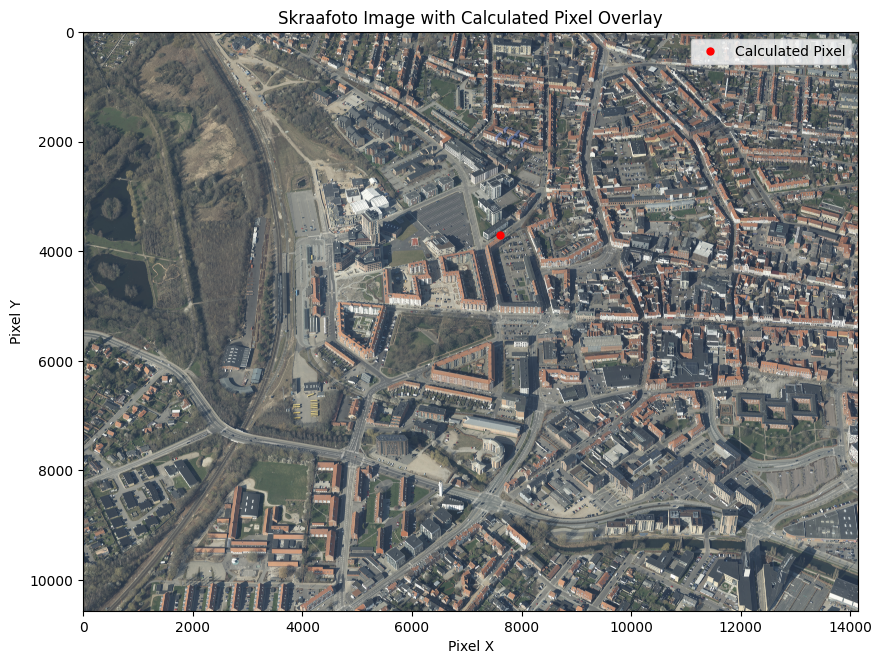

In [199]:
from utils import plots

plots.plot_pixel_on_image(projected_points, img)

In [181]:
img = skraafoto.get_image_from_url(img_url)

In [7]:
from georeferencing import pixel_to_latlong

result = pixel_to_latlong.split_image_and_compute_homographies(img,item)

/Users/kristinajassova/Library/Caches/pypoetry/virtualenvs/bachelor-project-18kCXu1E-py3.12/lib/python3.12/site-packages/PIL/Image.py:3402: DecompressionBombWarning: Image size (149360640 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(


✔ Found elevation at offset (-2, -2): 0.79392618
✔ Found elevation at offset (-2, -2): 3.1098347
✔ Found elevation at offset (-2, -2): 18.418369
✔ Found elevation at offset (-2, -2): 1.3570112
✔ Found elevation at offset (-2, -2): 0.63056141
✔ Found elevation at offset (-2, -2): 1.7936331
✔ Found elevation at offset (-2, -2): 1.6400118
✔ Found elevation at offset (-2, -2): 1.7011753


In [8]:
result['homographies']

{'tile_1[9.828368773330094,55.86313533465646,9.840934302402239,55.8696539661694]': array([[ 3.00225766e-06, -2.54752369e-04,  9.83152893e+00],
        [ 9.66657277e-06, -1.44520203e-03,  5.58567314e+01],
        [ 1.73283691e-07, -2.58894019e-05,  1.00000000e+00]]),
 'tile_2[9.840934302402239,55.86313533465646,9.853499831474384,55.8696539661694]': array([[-1.24583219e-06, -2.35213615e-04,  9.83137262e+00],
        [-1.45305446e-05, -1.33434239e-03,  5.58568957e+01],
        [-2.59516709e-07, -2.39049206e-05,  1.00000000e+00]]),
 'tile_3[9.828368773330094,55.85661670314353,9.840934302402239,55.86313533465646]': array([[ 9.66175947e-06, -2.80228122e-04,  9.83157722e+00],
        [ 4.76094118e-05, -1.58992976e-03,  5.58567367e+01],
        [ 8.52385298e-07, -2.84801500e-05,  1.00000000e+00]]),
 'tile_4[9.840934302402239,55.85661670314353,9.853499831474384,55.86313533465646]': array([[-1.40513612e-06, -2.41560049e-04,  9.83151563e+00],
        [-1.53027595e-05, -1.37042077e-03,  5.58567663

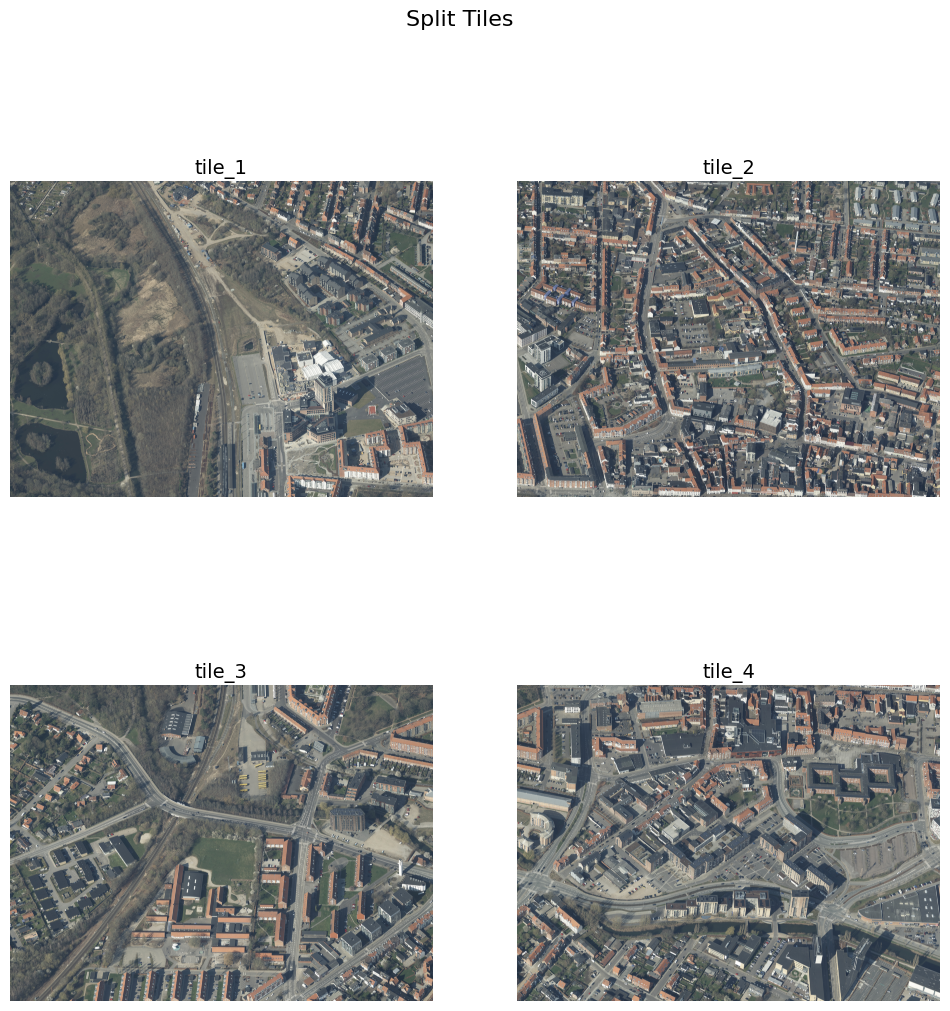

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(12, 12))  

tiles = result['tiles']
tile_order = [
        ("tile_1", 0, 0), 
        ("tile_2", 0, 1), 
        ("tile_3", 1, 0),  
        ("tile_4", 1, 1),  
    ]

for tile_name, row, col in tile_order:
        if tile_name in tiles:  
            axes[row, col].imshow(tiles[tile_name])  
            axes[row, col].set_title(tile_name, fontsize=14)  
            axes[row, col].axis("off") 

plt.suptitle("Split Tiles", fontsize=16)
plt.show()

In [45]:
import random
import folium
from PIL import Image
import io


imgg = Image.open(io.BytesIO(img.content))
w, h = imgg.size 


/Users/kristinajassova/Library/Caches/pypoetry/virtualenvs/bachelor-project-18kCXu1E-py3.12/lib/python3.12/site-packages/PIL/Image.py:3402: DecompressionBombWarning: Image size (149360640 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(


In [57]:
# Find the correct tile and homography
random_pixel_x = random.randint(0, w - 1)
random_pixel_y = random.randint(0, h - 1)
tile_name, homography = pixel_to_latlong.find_tile_for_pixel(random_pixel_x, random_pixel_y, result['homographies'], item)

✔ Found elevation at offset (-2, 0): 15.47384
Tile: tile_1[9.828368773330094,55.86313533465646,9.840934302402239,55.8696539661694]
Bounding Box in Pixels: x_min=-1050.450300712654, x_max=7053.478284899267, y_min=6060.504151036048, y_max=10671.824997897433
Checking if (2719, 2540) falls inside...

✔ Found elevation at offset (-2, -2): 1.9870224
Tile: tile_2[9.840934302402239,55.86313533465646,9.853499831474384,55.8696539661694]
Bounding Box in Pixels: x_min=7152.126407684175, x_max=14105.97801635773, y_min=6110.192079633928, y_max=10825.723543397029
Checking if (2719, 2540) falls inside...

Tile: tile_3[9.828368773330094,55.85661670314353,9.840934302402239,55.86313533465646]
Bounding Box in Pixels: x_min=-2525.3469390085656, x_max=7152.124863968655, y_min=-144.6639314718689, y_max=6109.548935043421
Checking if (2719, 2540) falls inside...



In [58]:
tile_name, homography

('tile_3[9.828368773330094,55.85661670314353,9.840934302402239,55.86313533465646]',
 array([[ 9.66175947e-06, -2.80228122e-04,  9.83157722e+00],
        [ 4.76094118e-05, -1.58992976e-03,  5.58567367e+01],
        [ 8.52385298e-07, -2.84801500e-05,  1.00000000e+00]]))

In [59]:

if homography is not None:
    # Convert pixel to real-world coordinates
    lon, lat = pixel_to_latlong.convert_pixel_to_world_homography(random_pixel_x, random_pixel_y, homography)

    print(f"Random Pixel: ({random_pixel_x}, {random_pixel_y})")
    print(f"Belongs to: {tile_name}")
    print(f"Computed Location: (Lat: {lat}, Lon: {lon})")

    bbox = item['bbox']
    # Plot the point on a map
    map_center = [(bbox[1] + bbox[3]) / 2, (bbox[0] + bbox[2]) / 2]  # Center map at the image bounding box
    m = folium.Map(location=map_center, zoom_start=15)
    
    # Add marker for the computed location
    folium.Marker(
        location=[lat, lon],
        popup=f"Transformed Point\nLat: {lat}, Lon: {lon}",
        icon=folium.Icon(color="red", icon="info-sign")
    ).add_to(m)
    
    # Show map
    m.save("output_map.html")
    print("Map saved as output_map.html. Open in a browser to view.")

else:
    print("Failed to find corresponding tile.")

Random Pixel: (2719, 2540)
Belongs to: tile_3[9.828368773330094,55.85661670314353,9.840934302402239,55.86313533465646]
Computed Location: (Lat: 55.8591299850996, Lon: 9.834713912223997)
Map saved as output_map.html. Open in a browser to view.


In [60]:
random_pixel_x, random_pixel_y

(2719, 2540)

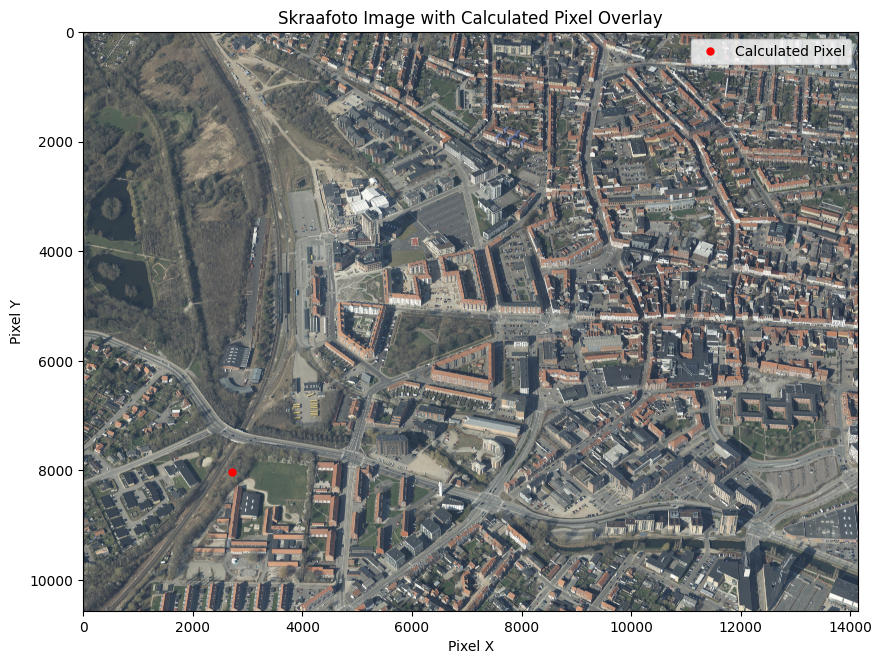

In [61]:
plots.plot_pixel_on_image([random_pixel_x,random_pixel_y],img)